In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
wine = load_wine()

X = wine.data
y_true = wine.target

print("Размер датасета:", X.shape)
print("Количество сортов:", len(np.unique(y_true)))
print("Названия сортов:", wine.target_names)

Размер датасета: (178, 13)
Количество сортов: 3
Названия сортов: ['class_0' 'class_1' 'class_2']


In [3]:
df = pd.DataFrame(X, columns=wine.feature_names)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Масштабирование завершено!")

Масштабирование завершено!


In [5]:
dbscan = DBSCAN(eps=1.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

print("Количество кластеров:", len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))
print("Количество выбросов:", list(dbscan_labels).count(-1))

Количество кластеров: 0
Количество выбросов: 178


In [6]:
if len(set(dbscan_labels)) > 1 and len(set(dbscan_labels)) < len(dbscan_labels):
    dbscan_silhouette = silhouette_score(X_scaled, dbscan_labels)
else:
    dbscan_silhouette = np.nan

dbscan_ari = adjusted_rand_score(y_true, dbscan_labels)

print("DBSCAN:")
print("Silhouette Score:", dbscan_silhouette)
print("Adjusted Rand Score:", dbscan_ari)

DBSCAN:
Silhouette Score: nan
Adjusted Rand Score: 0.0


In [7]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Количество кластеров:", len(np.unique(kmeans_labels)))

Количество кластеров: 3


In [8]:
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_ari = adjusted_rand_score(y_true, kmeans_labels)

print("KMeans:")
print("Silhouette Score:", kmeans_silhouette)
print("Adjusted Rand Score:", kmeans_ari)

KMeans:
Silhouette Score: 0.2848589191898987
Adjusted Rand Score: 0.8974949815093207


In [9]:
results = pd.DataFrame({
    "Алгоритм": ["DBSCAN", "KMeans"],
    "Silhouette Score": [dbscan_silhouette, kmeans_silhouette],
    "Adjusted Rand Score": [dbscan_ari, kmeans_ari]
})

display(results)

,Алгоритм,Silhouette Score,Adjusted Rand Score
0,DBSCAN,NaN,0.000000
1,KMeans,0.284859,0.897495


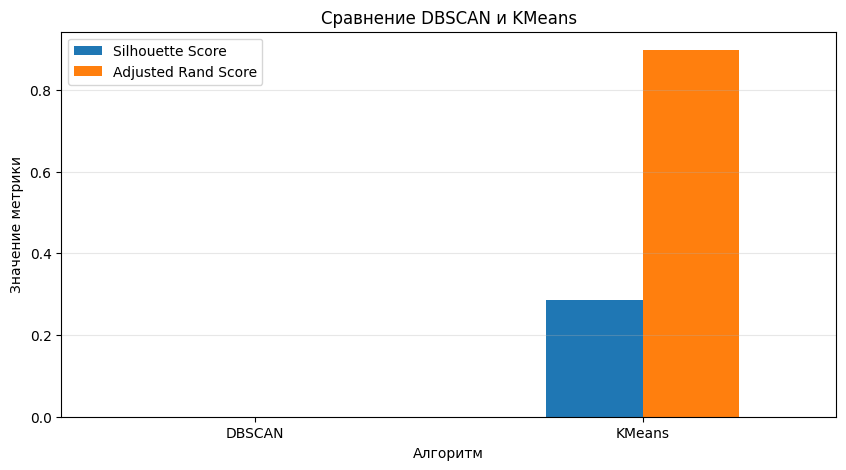

In [10]:
results.set_index("Алгоритм").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Сравнение DBSCAN и KMeans")
plt.ylabel("Значение метрики")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

DBSCAN выполняет кластеризацию на основе плотности объектов и способен выделять выбросы. KMeans разделяет данные на заранее заданное количество кластеров.

Для оценки качества использовались метрики Silhouette Score и Adjusted Rand Score. Первая оценивает компактность и разделённость кластеров, вторая показывает соответствие найденных кластеров истинным сортам вина.

Лучший алгоритм определяется по полученным значениям метрик. Для поиска истинных сортов особенно важен Adjusted Rand Score: чем он выше, тем лучше результат кластеризации соответствует реальным классам.